In [1]:
import torch
from torch import nn, optim
import torch.nn.functional as F

In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
import math

In [5]:
import matplotlib.pyplot as plt

In [6]:
from string import punctuation

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Baixe o pacote de dados necessário (apenas na primeira execução)
nltk.download('punkt_tab')

# 1. Baixe o pacote de dados de stopwords (necessário apenas na primeira vez)
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [10]:
import time

In [11]:
# 2. Carregue a lista de stopwords em inglês
stopwords_temp = stopwords.words('english')
stopwords_temp.extend( ['—', '’'] )
stopwords_ingles = set(stopwords_temp)
# stopwords_ingles

In [12]:
df = pd.read_csv("C:\\git\\dados\\nlp\\news_sentiment_analysis.csv", encoding="utf-8")
df = df[["Description"]]
df

,Description
0,"ST. GEORGE — Kaitlyn Larson, a first-year teac..."
1,"Harare, Zimbabwe – Local businesses are grappl..."
2,(marketscreener.com) Billionaire Elon Musk has...
3,(marketscreener.com) A U.S. trade regulator on...
4,4.5 million households in the U.S. have solar ...
...,...
3495,QRG Capital Management Inc. increased its stak...
3496,QRG Capital Management Inc. bought a new posit...
3497,QRG Capital Management Inc. boosted its stake ...
3498,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --..."


In [13]:
def limpar_texto( texto ):
    tokens_limpas = []
    tabela = str.maketrans("", "", punctuation)
    texto_limpo = texto.lower().translate( tabela )
    tokens = word_tokenize(texto_limpo)
    for token in tokens:
        if token not in stopwords_ingles and len(token) <= 15:
            tokens_limpas.append( token )
    return " ".join(tokens_limpas)
            

In [14]:
limpar_texto(df["Description"][0])

'st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams 8230'

In [15]:
df["descricao_limpa"] = df["Description"].apply( limpar_texto )
df

,Description,descricao_limpa
0,"ST. GEORGE — Kaitlyn Larson, a first-year teac...",st george kaitlyn larson firstyear teacher pin...
1,"Harare, Zimbabwe – Local businesses are grappl...",harare zimbabwe – local businesses grappling s...
2,(marketscreener.com) Billionaire Elon Musk has...,billionaire elon musk donated super pac workin...
3,(marketscreener.com) A U.S. trade regulator on...,us trade regulator fridayannounced suite actio...
4,4.5 million households in the U.S. have solar ...,45 million households us solar panels homes cu...
...,...,...
3495,QRG Capital Management Inc. increased its stak...,qrg capital management inc increased stake sha...
3496,QRG Capital Management Inc. bought a new posit...,qrg capital management inc bought new position...
3497,QRG Capital Management Inc. boosted its stake ...,qrg capital management inc boosted stake akama...
3498,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --...",westford mass july 18 2024 prnewswire accordin...


In [16]:
df["descricao_limpa"].loc[0]

'st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams 8230'

In [17]:
entrada = "st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams"
saida = "8230"

In [18]:
entrada = "st george kaitlyn"
saida = "larson"

In [19]:
entrada = "st george kaitlyn larson"
saida = "firstyear"

In [20]:
entrada = "st george kaitlyn larson firstyear"
saida = "teacher" 
# ...

In [21]:
frases_selecionadas = df["descricao_limpa"].loc[0:10]
frases_selecionadas

0     st george kaitlyn larson firstyear teacher pin...
1     harare zimbabwe – local businesses grappling s...
2     billionaire elon musk donated super pac workin...
3     us trade regulator fridayannounced suite actio...
4     45 million households us solar panels homes cu...
5     billionaire investor mario firm seeking detail...
6     july 12 2024 508 pm qwi announces close busine...
7     rome resources ltd pleased announce special me...
8     business reporter potentially bruising fight g...
9     creative strategies deep industry knowledge sp...
10    ill drink kirland ellis partner flexes dexteri...
Name: descricao_limpa, dtype: str

In [22]:
novas_frases = []
saidas = []
for texto in df["descricao_limpa"]:
    tokens = word_tokenize(texto)
    for indice_token in range(3, len(tokens)):
        tokens_entrada = tokens[:indice_token]
        saida = tokens[indice_token]
        novas_frases.append(tokens_entrada)
        saidas.append(saida)
# print(novas_frases)
# print(saidas)  

In [23]:
len(novas_frases)

109307

In [24]:
dicionario = {"<PADDING>": 0, "<UNKNOWN>": 1}
# dicionario_contagem = {}
dicionario

{'<PADDING>': 0, '<UNKNOWN>': 1}

In [25]:
MAX_PALAVRAS = 5000

In [27]:
frases_numeradas = []
contador_palavras = len(dicionario)
for tokens in novas_frases:
    frase_number = []
    for token in tokens:
        if token not in dicionario.keys():
            if contador_palavras < MAX_PALAVRAS:
                dicionario[token] = contador_palavras
                contador_palavras = contador_palavras + 1
                valor = dicionario[token]
            else:
                valor = dicionario["<UNKNOWN>"]
        else:
            valor = dicionario[token]
        frase_number.append(valor)
    frases_numeradas.append(frase_number)
frases_numeradas

[[2, 3, 4],
 [2, 3, 4, 5],
 [2, 3, 4, 5, 6],
 [2, 3, 4, 5, 6, 7],
 [2, 3, 4, 5, 6, 7, 8],
 [2, 3, 4, 5, 6, 7, 8, 9],
 [2, 3, 4, 5, 6, 7, 8, 9, 10],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5, 20],
 [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5, 20, 21],
 [2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  5,
  20,
  21,
  22],
 [2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
 

In [28]:
len(dicionario)

5000

In [47]:
# sorted_dicionario_contagem = dict(
#     sorted(dicionario_contagem.items(), key=lambda item: item[1])
# )
# lista = list(sorted_dicionario_contagem.items())
# lista.reverse()
# lista[:2000]

# novo_dicionario = {"<PADDING>": 0, "<UNKNOWN>": 1}
# for item in lista[:2000]:
#     chave, valor = item 
#     novo_dicionario[chave] = dicionario[chave]
# len(novo_dicionario)

2002

In [29]:
maior_frase = 0 
for frase in frases_numeradas:
    if len(frase) > maior_frase:
        maior_frase = len(frase)
maior_frase

103

In [32]:
# Fazer o padding
frases_padded = []
for frase in frases_numeradas:
    entrada = frase
    qtd_paddings = maior_frase - len(entrada)
    paddings = [dicionario["<PADDING>"] for _ in range(qtd_paddings)]
    # padding na direita
    # entrada = entrada + paddings
    
    # padding a esquerda
    entrada = paddings + entrada
    frases_padded.append(entrada)
len(frases_padded)

109307

In [55]:
# print(df["descricao_limpa"][0])
# print(df["frases_numeradas"][0])
# print(df["frases_padded"][0])
# print(df["saida"][0])

st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams 8230
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 26, 27, 32, 33, 34, 35]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 5, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 26, 27, 32, 33, 34]
35


### Frase
"st george kaitlyn larson firstyear teacher"

### Entrada
x0   x1     x2     x3      x4
st george kaitlyn larson firstyear
10   11    13       15    16      

### Saida
y
teacher
17


In [33]:
print("Classes possiveis ==>", len(dicionario))

Classes possiveis ==> 5000


In [36]:
X = torch.tensor(frases_padded, dtype=torch.int32)
print(X)
print(X.shape)    

tensor([[  0,   0,   0,  ...,   2,   3,   4],
        [  0,   0,   0,  ...,   3,   4,   5],
        [  0,   0,   0,  ...,   4,   5,   6],
        ...,
        [  0,   0,   0,  ..., 520,   1, 836],
        [  0,   0,   0,  ...,   1, 836, 453],
        [  0,   0,   0,  ..., 836, 453,   1]], dtype=torch.int32)
torch.Size([109307, 103])


In [38]:
saidas

['larson',
 'firstyear',
 'teacher',
 'pine',
 'view',
 'high',
 'school',
 'recently',
 'received',
 'best',
 'state',
 'award',
 'business',
 'leadership',
 'course',
 'larson',
 'students',
 'grades',
 '1012',
 'highest',
 'passing',
 'rate',
 'youscience',
 'exam',
 'spring',
 'fall',
 'semesters',
 '2023',
 'youscience',
 'exam',
 'similar',
 'final',
 'exams',
 '8230',
 'local',
 'businesses',
 'grappling',
 'severe',
 'liquidity',
 'crunch',
 'limiting',
 'donated',
 'super',
 'pac',
 'working',
 'elect',
 'former',
 'us',
 'president',
 'donald',
 'trump',
 'bloomberg',
 'reported',
 'friday',
 'citing',
 'sources',
 'report',
 'indicate',
 'much',
 'musk',
 'donated',
 'added',
 'sizable',
 'amount',
 'given',
 'group',
 'called',
 'america',
 'pac',
 'fridayannounced',
 'suite',
 'actions',
 'taking',
 'aim',
 'unfair',
 'said',
 'illegally',
 'imposed',
 'us',
 'franchisees',
 'bytheir',
 'brand',
 'owners',
 'requiring',
 'new',
 'fees',
 'outlined',
 'infranchise',
 'contr

In [40]:
saidas_numericas = []
for saida in saidas:
    valor = dicionario.get(saida, dicionario["<UNKNOWN>"])
    saidas_numericas.append(valor)

In [41]:
# Input tensor of class indices (must be integer/LongTensor)
labels = torch.tensor(saidas_numericas)

# Convert to one-hot vectors with 20903 classes
Y = F.one_hot(labels, num_classes=len(dicionario)).to(torch.float32)
print(Y)
print(Y.shape)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.]])
torch.Size([109307, 5000])


In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.9, random_state=50)

In [59]:
print("Shapes:")
print("X_train: ", X_train.shape)
print("Y_train: ", y_train.shape)
print("X_test: ", X_test.shape)
print("Y_test: ", y_test.shape)

Shapes:
X_train:  torch.Size([10930, 103])
Y_train:  torch.Size([10930, 5000])
X_test:  torch.Size([98377, 103])
Y_test:  torch.Size([98377, 5000])


In [60]:
class AdivinhaProximaPalavra( nn.Module ):
    def __init__(self, tamanho_entrada : int, numero_classes : int, tamanho_camada_hidden : int):
        super(AdivinhaProximaPalavra, self).__init__()
        global dicionario
        embedding_dim = 50
        self.embedding = nn.Embedding(num_embeddings = numero_classes, embedding_dim = embedding_dim, padding_idx = dicionario["<PADDING>"])
        self.lstm = nn.LSTM(input_size = embedding_dim,  hidden_size = tamanho_camada_hidden, batch_first = True)
        self.fc = nn.Linear(in_features = tamanho_camada_hidden, out_features = numero_classes)

    def forward(self, x):
        embedded = self.embedding( x )
        saida_lstm, (hidden, cell) = self.lstm( embedded )
        vetor_probabilidades = self.fc( cell[-1] )
        return vetor_probabilidades
        

In [61]:
modelo = AdivinhaProximaPalavra(tamanho_entrada = maior_frase, numero_classes = len(dicionario), tamanho_camada_hidden = 200)

In [62]:
perda = nn.CrossEntropyLoss()
perda

CrossEntropyLoss()

In [63]:
for param in modelo.parameters():
    print(param.data, " - ", param.data.shape)

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-1.5121, -0.9134,  0.6529,  ..., -1.5095,  0.4046,  0.8425],
        [-0.1706, -0.6471, -0.9619,  ...,  0.5508, -0.5276,  0.6525],
        ...,
        [ 0.2577, -1.0856,  0.2943,  ...,  1.1137,  0.1870, -1.7732],
        [ 1.8347,  0.4528,  0.3344,  ..., -0.5344, -0.5820,  0.5499],
        [ 0.8570, -0.1462,  1.1816,  ...,  0.8439,  1.5104, -0.7018]])  -  torch.Size([5000, 50])
tensor([[ 0.0414, -0.0512, -0.0348,  ..., -0.0387,  0.0570, -0.0145],
        [ 0.0195,  0.0463, -0.0083,  ...,  0.0235, -0.0199, -0.0695],
        [ 0.0271, -0.0303, -0.0497,  ..., -0.0251, -0.0101,  0.0265],
        ...,
        [-0.0064,  0.0640,  0.0496,  ...,  0.0424,  0.0274,  0.0372],
        [-0.0311,  0.0667,  0.0322,  ..., -0.0269,  0.0167,  0.0640],
        [-0.0315, -0.0630,  0.0006,  ...,  0.0397,  0.0188, -0.0008]])  -  torch.Size([800, 50])
tensor([[ 0.0488, -0.0115,  0.0546,  ...,  0.0311,  0.0138, -0.0422],
        [

In [64]:
otimizador = optim.Adam( modelo.parameters(), lr = 0.01)
otimizador

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)

In [65]:
epocas = 5
perdas = []
for epoca in range( epocas ):
    inicio = time.time()
    y_hat = modelo( X_train )
    loss = perda(y_hat, y_train)
    perdas.append( loss.tolist() )
    # Marca o tempo final
    fim = time.time()
    tempo_decorrido = fim - inicio
    print(f"Passaram-se {tempo_decorrido:.2f} segundos.")
    # if epoca % 20 == 0:
    print(loss)
    otimizador.zero_grad()
    loss.backward()
    otimizador.step()

Passaram-se 25.27 segundos.
tensor(8.5096, grad_fn=<DivBackward1>)
Passaram-se 5.57 segundos.
tensor(6.7319, grad_fn=<DivBackward1>)
Passaram-se 5.30 segundos.
tensor(10.7492, grad_fn=<DivBackward1>)
Passaram-se 5.49 segundos.
tensor(5.3195, grad_fn=<DivBackward1>)
Passaram-se 6.39 segundos.
tensor(5.8756, grad_fn=<DivBackward1>)


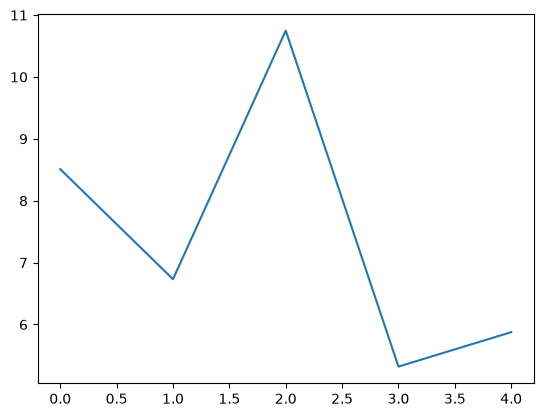

In [66]:
plt.plot( perdas )
plt.show()

In [67]:
acertos = 0
y_hats_tests = modelo(X_test)
print(y_hats_tests[0:5])

RuntimeError: [enforce fail at alloc_cpu.cpp:117] data. DefaultCPUAllocator: not enough memory: you tried to allocate 124669648896 bytes.

In [46]:
y_hat_max = torch.argmax(y_hats_tests, axis=1)
print(y_hat_max[0:5])

tensor([1, 0, 0, 1, 0])


In [72]:
# Dicionario reverso
dicionario_reverso = {}
for item in dicionario.items():
    chave, valor = item
    dicionario_reverso[valor] = chave
dicionario_reverso

{0: '<PADDING>',
 1: '<UNKNOWN>',
 2: 'st',
 3: 'george',
 4: 'kaitlyn',
 5: 'larson',
 6: 'firstyear',
 7: 'teacher',
 8: 'pine',
 9: 'view',
 10: 'high',
 11: 'school',
 12: 'recently',
 13: 'received',
 14: 'best',
 15: 'state',
 16: 'award',
 17: 'business',
 18: 'leadership',
 19: 'course',
 20: 'students',
 21: 'grades',
 22: '1012',
 23: 'highest',
 24: 'passing',
 25: 'rate',
 26: 'youscience',
 27: 'exam',
 28: 'spring',
 29: 'fall',
 30: 'semesters',
 31: '2023',
 32: 'similar',
 33: 'final',
 34: 'exams',
 35: '8230',
 36: 'harare',
 37: 'zimbabwe',
 38: '–',
 39: 'local',
 40: 'businesses',
 41: 'grappling',
 42: 'severe',
 43: 'liquidity',
 44: 'crunch',
 45: 'limiting',
 46: 'billionaire',
 47: 'elon',
 48: 'musk',
 49: 'donated',
 50: 'super',
 51: 'pac',
 52: 'working',
 53: 'elect',
 54: 'former',
 55: 'us',
 56: 'president',
 57: 'donald',
 58: 'trump',
 59: 'bloomberg',
 60: 'reported',
 61: 'friday',
 62: 'citing',
 63: 'sources',
 64: 'report',
 65: 'indicate',
 66

In [73]:
acertos = 0
y_hats_tests = modelo(X_test)
y_hats_tests_max = torch.argmax(y_hats_tests, axis=1)
y_test_max = torch.argmax(y_test, axis=1)
for idx, y_hat_test in enumerate(y_hats_tests):
    y_hat = y_hats_tests_max[idx]
    y = y_test_max[idx]  
    if y_hat == y:
        acertos = acertos + 1   
print(f"Porcentagem de acertos: {100*acertos/len(y_test):.2f}%")

Porcentagem de acertos: 70.06%


In [99]:
# acertos = 0
# for item_teste in range(1000, 2000):
#     # item_teste = 4
#     texto = df["descricao_limpa"][item_teste]
#     X_teste = vetorizador_teste.fit_transform( [texto] )
#     X_teste = torch.tensor(X_teste.toarray(), dtype=torch.float32)
#     y_hat = modelo(X_teste)
#     y = df["sentiment_number"][item_teste]
#     resultado = 1.0 if y_hat > 0.50 else 0.0
#     if resultado == y:
#         acertos = acertos + 1
#         # print("acertou")
#     else:
#         pass
#         # print("errou")
    
# print(f"Porcentagem de acertos: {100*acertos/1000:.2f}%")

Porcentagem de acertos: 99.90%


In [74]:
texto = "capital management inc bought new position"

def tokenizar_limpar_texto( texto ):
    tokens_limpas = []
    tabela = str.maketrans("", "", punctuation)
    texto_limpo = texto.lower().translate( tabela )
    tokens = word_tokenize(texto_limpo)
    for token in tokens:
        if token not in stopwords_ingles and len(token) <= 15:
            tokens_limpas.append( token )
    return tokens_limpas


In [76]:
frase_tokenizada = tokenizar_limpar_texto( texto )
frase_tokenizada

['capital', 'management', 'inc', 'bought', 'new', 'position']

In [78]:
frase_numerada = []
for token in frase_tokenizada:
    if token in dicionario:
        frase_numerada.append(dicionario[token])
    else:
        frase_numerada.append(dicionario["<UNKNOWN>"])
frase_numerada

[858, 463, 338, 1, 90, 1]

In [ ]:
# Adicionar o padding
qtd_paddings = maior_frase - len(frase_numerada)
paddings = [dicionario["<PADDING>"] for _ in range(qtd_paddings)]
frase_padded = paddings + frase_numerada
frase_padded

In [83]:
entrada_teste = torch.tensor( [frase_padded], dtype=torch.int32 )
logits_palavra_predict = modelo( entrada_teste )
indice_palavra_prevista = torch.argmax( logits_palavra_predict ).item()
print("Indice da palavra prevista: ", indice_palavra_prevista)
palavra = dicionario_reverso[indice_palavra_prevista]
print("Palavra: ", palavra)

Indice da palavra prevista:  533
Palavra:  additional
